# Chunked Inference

The 03 encoder reads only the first 128 and the last 382 tokens of a text. This notebook first shows that it is weaker on long texts, then tests chunked inference: the same trained model scores several windows of each text and the window scores are combined into one prediction. Nothing is retrained. Scoring the windows needs a GPU and the 03 run attached (for its model); everything else loads from `ARTIFACTS_DIR`.

In [1]:
import sys
from pathlib import Path

# Make the repo importable: the local checkout, or a fresh clone on Kaggle/Colab. Then pin versions that must match.
REPO_URL = "https://github.com/BohdanZasymovych/ai-hw3-ai-text-detection.git"
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "setup_env.py").exists()), None)
if REPO is None:
    REPO = Path("/kaggle/working/hw3" if Path("/kaggle").exists() else "/content/hw3")
    if REPO.exists():
        !git -C {REPO} pull -q
    else:
        !git clone -q --depth 1 {REPO_URL} {REPO}
sys.path.insert(0, str(REPO))

import setup_env

setup_env.install_pins()

import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer

from utils import (ARTIFACTS_DIR, DATA_DIR, ENV, LABEL_ORDER, MODEL_COLORS, SEED, cached, class_report, compare_f1,
                   compare_groups, ensure_data, ensure_dirs, find_artifact, get_split, length_band, load_key, macro_f1,
                   plot_compare, plot_confusion, submit_to_kaggle, write_submission)
from utils.encoder import chunk_encode, combine_chunks, predict_logits
from utils.stacking import fit_predict, oof_predict, window_features

ensure_dirs()
ensure_data()
split = get_split()  # fixed train/val split, made and cached on first use
gpu = f"{torch.cuda.device_count()}x {torch.cuda.get_device_name(0)}" if torch.cuda.is_available() else "none"
print(f"env={ENV}  gpu={gpu}  data={DATA_DIR}  artifacts={ARTIFACTS_DIR}")

SUBMIT = False  # True: save the test predictions and upload the submission to Kaggle (5 uploads a day)

/home/bohdan/code/ai/hw3-ai-text-detection/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/split.pkl
env=local  gpu=none  data=/home/bohdan/code/ai/hw3-ai-text-detection/data  artifacts=/home/bohdan/code/ai/hw3-ai-text-detection/artifacts


## Data

Load the fixed validation split and the test set, and the saved results of the earlier notebooks: the 03 encoder's validation logits and token counts, and the validation scores of TF-IDF 50k (02). No training data is needed.

In [2]:
train_full = pd.read_csv(DATA_DIR / "train.csv")
val = train_full.iloc[split["val"]].reset_index(drop=True)
del train_full
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
label_order = np.array(LABEL_ORDER)

ENC_KEY = load_key("encoder_val_logits")  # settings of the 03 encoder run
assert ENC_KEY is not None, "03 results not found: attach the 03_encoder output or copy its artifacts"
assert load_key("baseline_val_scores")["checksum"] == ENC_KEY["checksum"], "baseline used a different subsample"
with open(find_artifact("enc_ids_val"), "rb") as f:
    val["tokens"] = pickle.load(f)["n_tokens"]
val["band"] = length_band(val["tokens"])
preds = {
    "TF-IDF 50k": label_order[np.load(find_artifact("baseline_val_scores", "npy")).argmax(axis=1)],
    "XLM-R base 50k": label_order[np.load(find_artifact("encoder_val_logits", "npy")).argmax(axis=1)],
}

pd.DataFrame({"texts": [len(val), len(test)]}, index=["validation", "test"])

,texts
validation,27238
test,25000


## Long Texts

Macro-F1 of XLM-R base 50k and TF-IDF 50k by text length in encoder tokens (left), and the median share of a text of $n$ tokens that the encoder sees, $\min(n, 510) / n$ (right).

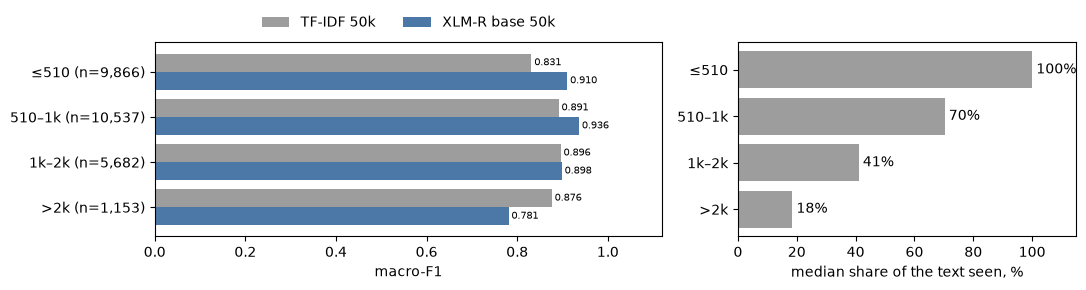

In [3]:
SEEN = ENC_KEY["head"] + ENC_KEY["tail"]  # tokens the 03 encoder reads per text
share_seen = np.minimum(val["tokens"], SEEN) / val["tokens"] * 100
by_band = compare_groups(val, preds, "band")

fig, (ax_f1, ax_seen) = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [3, 2]})
plot_compare(by_band, ax_f1, MODEL_COLORS)
seen = share_seen.groupby(val["band"], observed=True).median()
ax_seen.barh(seen.index.astype(str), seen.values, color="#9D9D9D")
ax_seen.bar_label(ax_seen.containers[0], fmt="%.0f%%", padding=3)
ax_seen.set_xlim(0, 115)
ax_seen.set_xlabel("median share of the text seen, %")
ax_seen.invert_yaxis()
plt.tight_layout()
plt.show()

## Chunking

Each text is split into windows of 510 tokens (512 with `<s>` and `</s>`). A text that fits is one window, as before. A longer text of $n$ tokens gets $\lceil n / 510 \rceil$ windows, at most 8, spread evenly from its first to its last token. The table shows how much of the texts each approach sees. The windows are cached.

In [4]:
WINDOW, MAX_CHUNKS = 510, 8
chunk_key = {"tokenizer": ENC_KEY["tokenizer"], "n_val": len(val), "n_test": len(test), "window": WINDOW,
             "max_chunks": MAX_CHUNKS, "v": 1}
tokenizer = AutoTokenizer.from_pretrained(ENC_KEY["tokenizer"])
chunks = {name: cached(f"chunk_ids_{name}", lambda: chunk_encode(df["text"], tokenizer, WINDOW, MAX_CHUNKS),
                       key={**chunk_key, "part": name})
          for name, df in [("val", val), ("test", test)]}

n_windows = pd.Series(chunks["val"]["n_windows"])
band = val["band"]
pd.DataFrame({
    "texts": band.value_counts(sort=False),
    "windows per text": n_windows.groupby(band, observed=True).mean(),
    "seen, head + tail": share_seen.groupby(band, observed=True).median(),
    "seen, chunks": (np.minimum(val["tokens"], n_windows * WINDOW) / val["tokens"] * 100).groupby(band, observed=True).median(),
}).style.format({"texts": "{:,}", "windows per text": "{:.1f}", "seen, head + tail": "{:.0f}%", "seen, chunks": "{:.0f}%"})

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/chunk_ids_val.pkl
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/chunk_ids_test.pkl


,texts,windows per text,"seen, head + tail","seen, chunks"
band,,,,
≤510,"9,866",1.0,100%,100%
510–1k,"10,537",2.0,70%,100%
1k–2k,"5,682",3.1,41%,100%
>2k,"1,153",6.2,18%,100%


## Inference

Run the saved 03 model on every window of the validation and test texts. The window logits are cached, so comparing ways to combine them costs nothing.

In [5]:
infer_key = {"encoder": ENC_KEY, **chunk_key}
model_dir = find_artifact("encoder", kind="dir")  # the 03 model; needed only while the logits are not cached
chunk_logits = {name: cached(f"chunk_logits_{name}", lambda: predict_logits(model_dir, chunks[name]["ids"]),
                             key={**infer_key, "part": name}, kind="npy")
                for name in ["val", "test"]}

pd.DataFrame({"windows": [len(chunks[name]["ids"]) for name in chunk_logits]}, index=["validation", "test"])

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/chunk_logits_val.npy
[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/chunk_logits_test.npy


,windows
validation,55909
test,50285


## Evaluation

Validation macro-F1 of each way to combine the window scores of a text, next to head + tail (03): the mean of the window logits, the mean of the window probabilities, and the mean of the logits with the highest fusion score over the windows (one rewritten part is enough for fusion). The best one is used below.

In [6]:
METHODS = ["mean_logits", "mean_probs", "max_fusion"]
combined = {m: combine_chunks(chunk_logits["val"], chunks["val"]["doc"], len(val), m) for m in METHODS}
scores = {m: macro_f1(val["label"], label_order[c.argmax(axis=1)]) for m, c in combined.items()}
BEST = max(scores, key=scores.get)
preds["XLM-R base 50k, window mean"] = label_order[combined[BEST].argmax(axis=1)]
cached("chunk_val_metrics", lambda: {"best": BEST, **scores}, key=infer_key, kind="json")

pd.Series({"XLM-R base 50k (head + tail)": macro_f1(val["label"], preds["XLM-R base 50k"]), **{f"XLM-R base 50k (windows, {m})": s for m, s in scores.items()}}) \
    .to_frame("macro-F1").style.background_gradient(cmap="Blues").format("{:.3f}")

[cache] loaded /home/bohdan/code/ai/hw3-ai-text-detection/artifacts/chunk_val_metrics.json


,macro-F1
XLM-R base 50k (head + tail),0.911
"XLM-R base 50k (windows, mean_logits)",0.800
"XLM-R base 50k (windows, mean_probs)",0.799
"XLM-R base 50k (windows, max_fusion)",0.762


Per-class scores of XLM-R base 50k, window mean.

In [7]:
class_report(val["label"], preds["XLM-R base 50k, window mean"]).style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "support": "{:,.0f}"})

,precision,recall,f1,support
human,0.912,0.461,0.612,"6,675"
ai,0.988,0.988,0.988,"12,194"
fusion,0.686,0.957,0.799,"8,369"
macro avg,0.862,0.802,0.800,"27,238"


Confusion matrix. Colours show the share of each true class; the counts are in brackets.

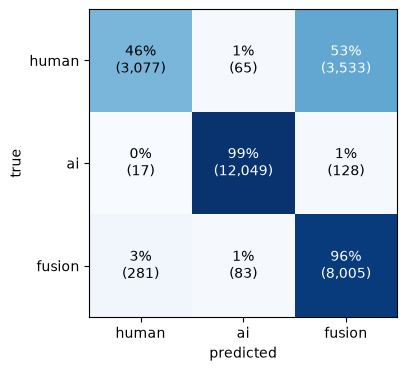

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_confusion(val["label"], preds["XLM-R base 50k, window mean"], ax)
plt.show()

Macro-F1 of single windows by their position, for texts with at least 3 windows (each window scored alone). Similar values mean the head + tail model also works on windows from the middle of a text, so training on chunks is not needed.

In [9]:
doc, pos = chunks["val"]["doc"], chunks["val"]["pos"]
k = chunks["val"]["n_windows"][doc]
windows = pd.DataFrame({
    "position": np.select([pos == 0, pos == k - 1], ["first", "last"], "middle"),
    "label": val["label"].to_numpy()[doc],
    "pred": label_order[chunk_logits["val"].argmax(axis=1)],
})[k >= 3]
pd.DataFrame({p: {"macro-F1": macro_f1(g["label"], g["pred"]), "windows": len(g)} for p, g in windows.groupby("position")}) \
    .T.reindex(["first", "middle", "last"]).style.format({"macro-F1": "{:.3f}", "windows": "{:,.0f}"})

,macro-F1,windows
first,0.625,"6,519"
middle,0.567,"11,299"
last,0.817,"6,519"


## Window Features

A plain average treats every window alike, but the model misreads windows from the middle of a text (above). Instead, a stacker (logistic regression on standardised inputs) gets the 03 head + tail logits and, from the window logits of each text, the first, last, mean, minimum and maximum window logits and $\log k$ for $k$ windows (19 numbers per text), and learns how much to trust each. Every validation row is predicted out-of-fold (5-fold cross-validation inside the validation set), so no row is scored by a stacker that saw it. `Stack: XLM-R base` uses only the 03 logits, to separate the gain of the windows from the gain of the stacker itself.

In [10]:
features = {name: np.hstack([np.load(find_artifact(f"encoder_{name}_logits", "npy")),
                             window_features(chunk_logits[name], chunks[name]["doc"], chunks[name]["n_windows"])])
            for name in ["val", "test"]}
y = val["label"].to_numpy()
stacked = {"Stack: XLM-R base": oof_predict(features["val"][:, :3], y, SEED), "Stack: XLM-R base + windows": oof_predict(features["val"], y, SEED)}
preds["Stack: XLM-R base + windows"] = stacked["Stack: XLM-R base + windows"]

compare_f1(y, {"XLM-R base 50k": preds["XLM-R base 50k"], "XLM-R base 50k, window mean": preds["XLM-R base 50k, window mean"], **stacked}) \
    .style.background_gradient(cmap="Blues", axis=None).format("{:.3f}")

,XLM-R base 50k,"XLM-R base 50k, window mean",Stack: XLM-R base,Stack: XLM-R base + windows
human,0.853,0.612,0.868,0.902
ai,0.991,0.988,0.992,0.993
fusion,0.887,0.799,0.890,0.918
macro avg,0.911,0.800,0.917,0.938


Confusion matrix of `Stack: XLM-R base + windows`. Colours show the share of each true class; the counts are in brackets.

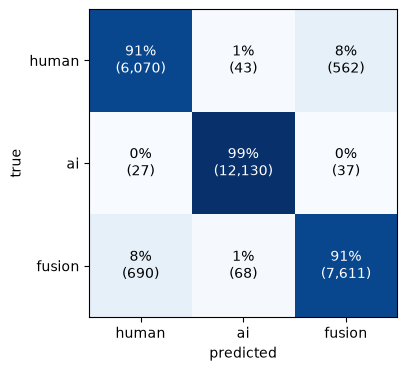

In [11]:
fig, ax = plt.subplots(figsize=(4.5, 4))
plot_confusion(val["label"], preds["Stack: XLM-R base + windows"], ax)
plt.show()

## Comparison with Baseline

F1 per class and macro-F1 of TF-IDF 50k, XLM-R base 50k (head + tail), `XLM-R base 50k, window mean` (plain average of the windows) and the two out-of-fold stackers (`Stack: XLM-R base`, `Stack: XLM-R base + windows`), on the same validation rows.

In [12]:
compare_f1(val["label"], preds).style.background_gradient(cmap="Blues", axis=None).format("{:.3f}")

,TF-IDF 50k,XLM-R base 50k,"XLM-R base 50k, window mean",Stack: XLM-R base + windows
human,0.807,0.853,0.612,0.902
ai,0.985,0.991,0.988,0.993
fusion,0.815,0.887,0.799,0.918
macro avg,0.869,0.911,0.800,0.938


Macro-F1 by text length (left) and by language and domain (right).

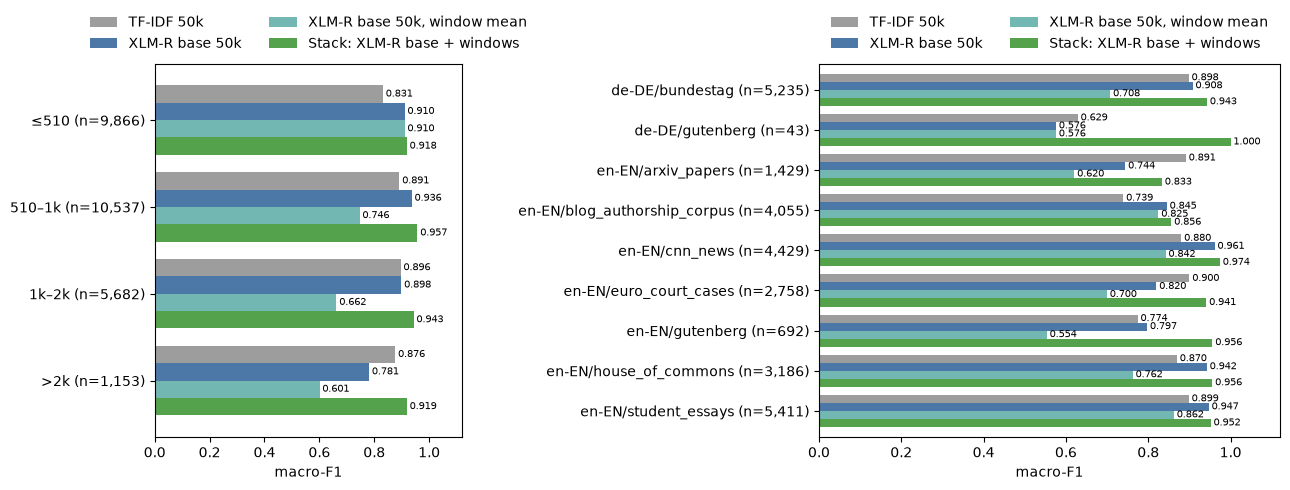

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 3]})
plot_compare(compare_groups(val, preds, "band"), axes[0], MODEL_COLORS)
plot_compare(compare_groups(val, preds, ["lang", "domain"]), axes[1], MODEL_COLORS)
plt.tight_layout()
plt.show()

## Submission

Test window logits are always predicted and cached (above), so later notebooks need no GPU for them. Only when `SUBMIT` is True, fit `Stack: XLM-R base + windows` on all validation rows, predict the test set, save a valid submission file and upload it to Kaggle. The upload is cached by the run settings, so rerunning the notebook does not spend another daily submission.

In [14]:
test_pred = fit_predict(features["val"], y, features["test"])

if SUBMIT:
    path = write_submission(test["id"], test_pred, sample_submission, "chunked")
    message = f"03 encoder + window-feature stacker (window {WINDOW}, max {MAX_CHUNKS}), val OOF macro-F1 {macro_f1(y, preds['Stack: XLM-R base + windows']):.3f}"
    cached("chunked_upload", lambda: submit_to_kaggle(path, message), key={**infer_key, "stacker": "windows", "seed": SEED}, kind="json")
    display(pd.Series(test_pred).value_counts(normalize=True).reindex(LABEL_ORDER).mul(100).round(1)
            .to_frame("share of test predictions, %").T)
else:
    print("SUBMIT is False: upload skipped")

SUBMIT is False: upload skipped


## Conclusions

- **Head + tail misses long texts.** On texts over 2k tokens the 03 encoder sees about 18% of the text and drops to 0.781 macro-F1 (TF-IDF: 0.876).
- **Averaging window scores fails** (0.800 vs 0.911): windows from the middle of a text score only 0.567 and are mostly read as fusion, because the head + tail model learned position cues.
- **Window logits work as stacker features:** 0.938 out-of-fold vs 0.917 for a stacker on the head + tail logits alone, with the gain on long texts. These window features (group C) are used in the final pipeline.